In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import re

In [2]:
fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

print("Fake News Dataset:")
print(fake_df.shape)

print("\nReal News Dataset:")
print(true_df.shape)

Fake News Dataset:
(23481, 4)

Real News Dataset:
(21417, 4)


In [3]:
print("Fake News:")
display(fake_df.head())

print("\nReal News:")
display(true_df.head())

print("\nColumns:")
print(fake_df.columns.tolist())

print("\nData Types:")
print(fake_df.dtypes)

Fake News:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



Real News:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"



Columns:
['title', 'text', 'subject', 'date']

Data Types:
title      object
text       object
subject    object
date       object
dtype: object


In [4]:
fake_df['label'] = 0
true_df['label'] = 1

df = pd.concat([fake_df, true_df], ignore_index=True)

print("Combined dataset shape:", df.shape)
print("\nClass distribution:")
print(df['label'].value_counts())

display(df.head())

Combined dataset shape: (44898, 5)

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df['label'].value_counts())

Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicate rows:
209

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [6]:

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("\nDuplicate rows after cleaning:", df.duplicated().sum())

Dataset shape after removing duplicates: (44689, 5)

Duplicate rows after cleaning: 0


## EDA Analysis

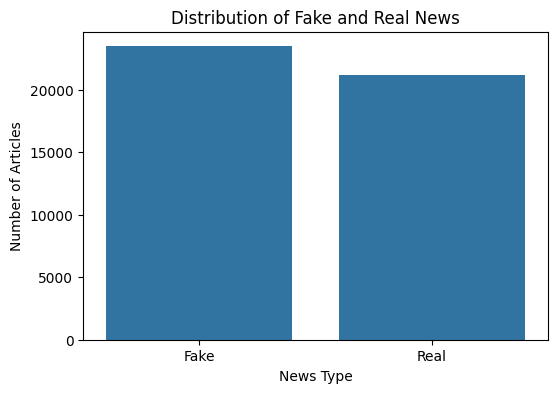

In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='label')

plt.title('Distribution of Fake and Real News')
plt.xlabel('News Type')
plt.ylabel('Number of Articles')
plt.xticks([0, 1], ['Fake', 'Real'])

plt.show()

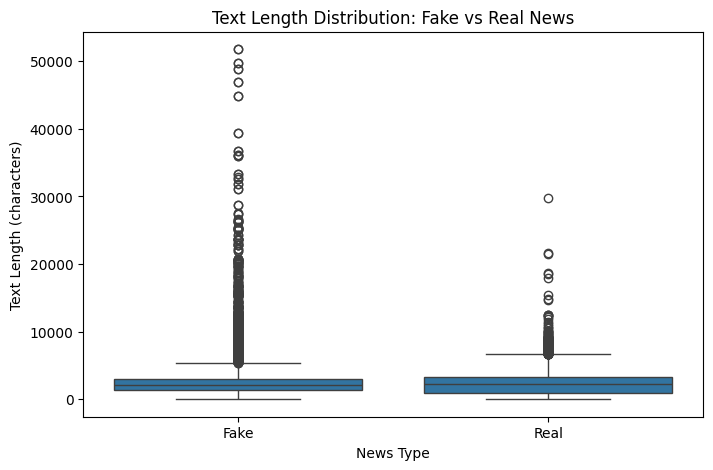

In [8]:
df['text_length'] = df['text'].str.len()

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='label', y='text_length')

plt.title('Text Length Distribution: Fake vs Real News')
plt.xlabel('News Type')
plt.ylabel('Text Length (characters)')
plt.xticks([0, 1], ['Fake', 'Real'])

plt.show()

In [9]:
print("Average text length:")
print(df.groupby('label')['text_length'].mean())

print("\nMedian text length:")
print(df.groupby('label')['text_length'].median())

Average text length:
label
0    2547.555882
1    2378.042337
Name: text_length, dtype: float64

Median text length:
label
0    2166.0
1    2216.0
Name: text_length, dtype: float64


The average text length of Fake news articles is approximately 2548 characters, while Real news articles average approximately 2378 characters. The median text lengths are 2166 and 2216 characters respectively. Although some long-text outliers are present, the central distributions are relatively similar. Therefore, text length alone is unlikely to be a strong distinguishing feature, and the actual textual content will be used for classification.

## Text preprocessing

### Combine title and text

In [10]:
df['content'] = df['title'] + " " + df['text']

print(df[['title', 'text', 'content']].head())

                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text  \
0  Donald Trump just couldn t wish all Americans ...   
1  House Intelligence Committee Chairman Devin Nu...   
2  On Friday, it was revealed that former Milwauk...   
3  On Christmas day, Donald Trump announced that ...   
4  Pope Francis used his annual Christmas Day mes...   

                                             content  
0   Donald Trump Sends Out Embarrassing New Year’...  
1   Drunk Bragging Trump Staffer Started Russian ...  
2   Sheriff David Clarke Becomes An Internet Joke...  
3   Trump Is So Obsessed He Even Has Obama’s Name...  
4   Pope Francis Just Called Out Donald Trump Dur..

### Clean the text

In [11]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['cleaned_text'] = df['content'].apply(clean_text)

display(df[['content', 'cleaned_text']].head())

,content,cleaned_text
0,Donald Trump Sends Out Embarrassing New Year’...,donald trump sends out embarrassing new year s...
1,Drunk Bragging Trump Staffer Started Russian ...,drunk bragging trump staffer started russian c...
2,Sheriff David Clarke Becomes An Internet Joke...,sheriff david clarke becomes an internet joke ...
3,Trump Is So Obsessed He Even Has Obama’s Name...,trump is so obsessed he even has obama s name ...
4,Pope Francis Just Called Out Donald Trump Dur...,pope francis just called out donald trump duri...


### Train-test split

In [12]:
X = df['cleaned_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 35751
Testing samples: 8938

Training class distribution:
label
0    18782
1    16969
Name: count, dtype: int64

Testing class distribution:
label
0    4696
1    4242
Name: count, dtype: int64


### TF-IDF

In [13]:
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35751, 50000)
Testing TF-IDF shape: (8938, 50000)


### Model 1: Logistic Regression


In [14]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_tfidf, y_train)

y_pred_log = log_model.predict(X_test_tfidf)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### Model 2: Multinomial Naive Bayes

In [15]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes training completed.")

Multinomial Naive Bayes training completed.


### Evaluate Logistic Regression

In [16]:
log_accuracy = accuracy_score(y_test, y_pred_log)
log_precision = precision_score(y_test, y_pred_log)
log_recall = recall_score(y_test, y_pred_log)
log_f1 = f1_score(y_test, y_pred_log)

print("Logistic Regression")
print("-------------------")
print(f"Accuracy : {log_accuracy:.4f}")
print(f"Precision: {log_precision:.4f}")
print(f"Recall   : {log_recall:.4f}")
print(f"F1-Score : {log_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=['Fake', 'Real']
))

Logistic Regression
-------------------
Accuracy : 0.9893
Precision: 0.9859
Recall   : 0.9915
F1-Score : 0.9887

Classification Report:
              precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      4696
        Real       0.99      0.99      0.99      4242

    accuracy                           0.99      8938
   macro avg       0.99      0.99      0.99      8938
weighted avg       0.99      0.99      0.99      8938



### Evaluate Naive Bayes

In [17]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(y_test, y_pred_nb)
nb_recall = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)

print("Multinomial Naive Bayes")
print("-----------------------")
print(f"Accuracy : {nb_accuracy:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall   : {nb_recall:.4f}")
print(f"F1-Score : {nb_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=['Fake', 'Real']
))

Multinomial Naive Bayes
-----------------------
Accuracy : 0.9530
Precision: 0.9492
Recall   : 0.9519
F1-Score : 0.9506

Classification Report:
              precision    recall  f1-score   support

        Fake       0.96      0.95      0.96      4696
        Real       0.95      0.95      0.95      4242

    accuracy                           0.95      8938
   macro avg       0.95      0.95      0.95      8938
weighted avg       0.95      0.95      0.95      8938



### Confusion matrices

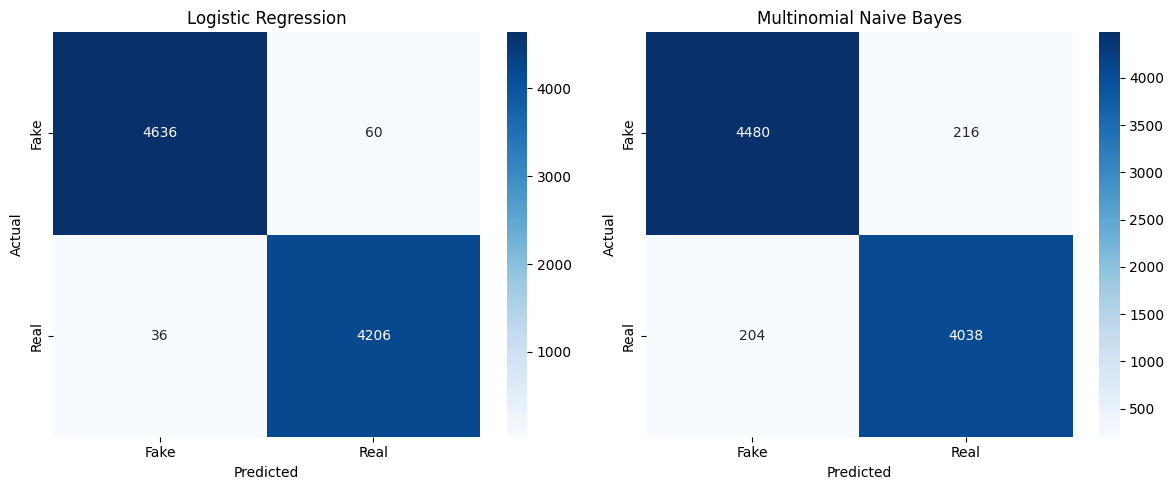

Logistic Regression Confusion Matrix:
[[4636   60]
 [  36 4206]]

Naive Bayes Confusion Matrix:
[[4480  216]
 [ 204 4038]]


In [18]:
cm_log = confusion_matrix(y_test, y_pred_log)
cm_nb = confusion_matrix(y_test, y_pred_nb)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real'],
    ax=axes[0]
)
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real'],
    ax=axes[1]
)
axes[1].set_title('Multinomial Naive Bayes')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

print("Logistic Regression Confusion Matrix:")
print(cm_log)

print("\nNaive Bayes Confusion Matrix:")
print(cm_nb)

## Final model comparison


In [19]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Multinomial Naive Bayes'],
    'Accuracy': [log_accuracy, nb_accuracy],
    'Precision': [log_precision, nb_precision],
    'Recall': [log_recall, nb_recall],
    'F1-Score': [log_f1, nb_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.989259,0.985935,0.991513,0.988717
1,Multinomial Naive Bayes,0.953010,0.949224,0.951909,0.950565


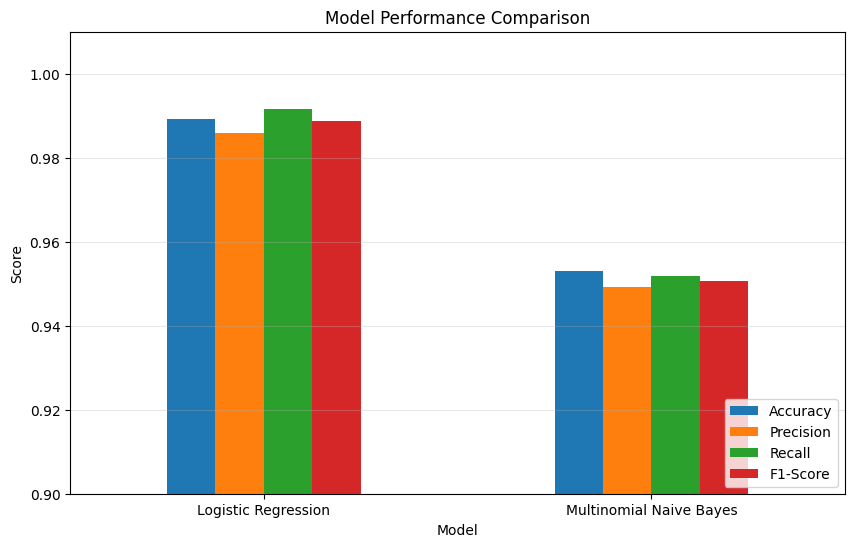

In [20]:
comparison_plot = comparison.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0.90, 1.01)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.show()

## Best Model Selection

Two machine learning models were implemented and evaluated for fake news detection: Logistic Regression and Multinomial Naive Bayes.

Logistic Regression achieved an accuracy of 98.93%, precision of 98.59%, recall of 99.15%, and F1-score of 98.87%. Multinomial Naive Bayes achieved an accuracy of 95.30%, precision of 94.92%, recall of 95.19%, and F1-score of 95.06%.

Logistic Regression performed better than Multinomial Naive Bayes across all four evaluation metrics. It also produced fewer classification errors in the confusion matrix, with 96 misclassified articles compared with 420 misclassified articles for Multinomial Naive Bayes.

Therefore, Logistic Regression was selected as the best-performing model for this fake news detection project.

## Conclusion

In this project, a machine-learning based fake news detection system was developed to classify news articles as Fake or Real. The dataset contained 44,898 news articles, and after removing 209 duplicate records, 44,689 articles were used for analysis.

The news title and article text were combined and cleaned through text preprocessing. TF-IDF was then used to convert the textual data into numerical features. The dataset was divided into 80% training data and 20% testing data using stratified sampling.

Two classification algorithms, Logistic Regression and Multinomial Naive Bayes, were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Logistic Regression achieved the best overall performance with 98.93% accuracy and an F1-score of 98.87%. Therefore, it was selected as the final model for fake news classification.

The results demonstrate that traditional machine-learning techniques combined with TF-IDF can effectively classify the news articles in this dataset.

## Future Improvements

The project can be improved in several ways:

- Use advanced NLP techniques such as word embeddings and transformer-based models.
- Experiment with models such as Linear SVM, Random Forest, or gradient boosting.
- Perform hyperparameter tuning to improve model performance.
- Use larger and more diverse datasets containing news from different sources and time periods.
- Analyze source credibility and author-related information.
- Deploy the trained model as a web application for real-time fake news classification.
- Continuously update the model with newly collected news articles.

In [21]:
def predict_news(title, text):
    # Combine title and article text
    content = title + " " + text
    
    # Apply the same preprocessing used during training
    cleaned_content = clean_text(content)
    
    # Convert text into TF-IDF features
    news_tfidf = tfidf.transform([cleaned_content])
    
    # Make prediction
    prediction = log_model.predict(news_tfidf)[0]
    
    # Get prediction probabilities
    probabilities = log_model.predict_proba(news_tfidf)[0]
    
    if prediction == 0:
        result = "FAKE"
        confidence = probabilities[0]
    else:
        result = "REAL"
        confidence = probabilities[1]
    
    print("Prediction:", result)
    print(f"Confidence: {confidence * 100:.2f}%")

In [23]:
title = input("Enter the news headline: ")
text = input("Enter the news article: ")

predict_news(title, text)

Prediction: FAKE
Confidence: 87.49%


## Real-World Prediction Demonstration

The trained Logistic Regression model was tested on previously unseen news articles.

1. A genuine Reuters news article was provided to the model.
   Prediction: REAL
   Confidence: 65.88%

2. A fictionalized article containing a false claim about the Apollo 11
   moon landing was provided to the model.
   Prediction: FAKE
   Confidence: 87.49%

These examples demonstrate how the trained model can accept new
news content and classify it as Fake or Real along with its predicted
confidence.